<a href="https://colab.research.google.com/github/eduzegarra/grade_01/blob/main/info_05_modelos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import pandas as pd
os.chdir('/content/drive/MyDrive/a_SENAMHI/OUT/')
!ls


base_final.csv	     comercio.dta    informacion.dta  top_regions.csv
caracteristicas.dta  coord_prod.csv  mq_eq.dta	      vbpagri.dta
caratulas.dta	     costos.dta      sf.dta
cofert.dta	     edu.dta	     supag.dta


In [3]:
df = pd.read_csv('base_final.csv', low_memory=False)

In [4]:
### nos quedamos con observaciones validas para info_5 y t_vbpagri

df_val=df.loc[(df.info_5.notna()) & (df.t_vbpagri.notna()) ].copy()

In [5]:
columns_to_fill = df_val.filter(regex=r'maq|equ|t_comprador|t_destino').columns
df_val[columns_to_fill] = df_val[columns_to_fill].fillna(0)

In [6]:
df_val['t_ingagri'] = (df_val.t_vbpagri - df_val.cost_tot).astype(float)

In [7]:
df_val[['t_ingagri', 't_vbpagri', 'info_5', 't_supcose', 't_usomaq', 't_usoequ',
               't_afectacion', 't_credito', 't_destino3']].describe().transpose()

,count,mean,std,min,25%,50%,75%,max
t_ingagri,97726.0,236.500838,8593.807876,-148632.5150,-1.445,-0.08,7.32,1066589.76
t_vbpagri,97726.0,370.327804,10389.772222,0.0000,0.000,2.56,17.24,1194294.00
info_5,97726.0,0.241983,0.428286,0.0000,0.000,0.00,0.00,1.00
t_supcose,97726.0,9.863517,158.773579,0.0003,0.430,1.17,3.50,20431.30
t_usomaq,97726.0,0.364468,0.481283,0.0000,0.000,0.00,1.00,1.00
t_usoequ,97726.0,0.527219,0.499261,0.0000,0.000,1.00,1.00,1.00
t_afectacion,97726.0,0.636565,0.480991,0.0000,0.000,1.00,1.00,1.00
t_credito,97726.0,0.122383,0.327729,0.0000,0.000,0.00,0.00,1.00
t_destino3,97726.0,0.051603,0.221226,0.0000,0.000,0.00,0.00,1.00


In [8]:
# Create dummy variables for REGION, dropping the first category to avoid multicollinearity
region_dummies = pd.get_dummies(df_val['REGION'], prefix='region', drop_first=True, dtype=float)

# Join the region dummies back to our main enterprise dataframe
df_val = df_val.join(region_dummies)

In [9]:
## Convertimos algunas variables a logaritmos

import numpy as np
ll=['ingagri', 'vbpagri', 'supcose', 'supag']
for dd in ll:
  # Using np.maximum(0, ...) to guarantee that the input to log1p is non-negative and avoid warnings
  df_val['log_'+dd] = np.log1p(df_val['t_'+dd])

/usr/local/lib/python3.13/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)
/usr/local/lib/python3.13/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)


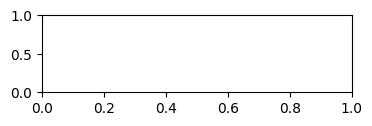

In [10]:
## excluimos cuando ingreso neto agrario es negativo
df_val.loc[df_val.log_ingagri<0, 'log_ingagri'] = np.nan

In [11]:
df_val.filter(regex='log').describe().transpose()

,count,mean,std,min,25%,50%,75%,max
log_ingagri,47032.0,2.389077,1.689148,0.000000,1.090496,2.199444,3.380723,13.879978
log_vbpagri,97726.0,1.729344,1.806384,0.000000,0.000000,1.269761,2.903617,13.993067
log_supcose,97726.0,1.084367,1.014395,0.000300,0.357674,0.774727,1.504077,9.924872
log_supag,97726.0,1.749845,1.189516,0.001998,0.875052,1.504077,2.351375,10.757924


In [12]:
!pip install -q linearmodels
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
from linearmodels.iv import IV2SLS

# 1. Create separate DataFrames for Empresas and Productores with explicit copies
df_emp = df_val.loc[df_val['tipo'] == 'Empresa'].copy()
df_pro = df_val.loc[df_val['tipo'] == 'Productor'].copy()

# 2. Define independent variables lists
region_cols = ['region_Sierra', 'region_Selva']

# Note: based on previous cell edits, the column name is t_usoequ (or t_usoequip/t_usoequ depending on data)
# Let's dynamically find the correct usage column name for equipment
# usoequ_col = 't_usoequ' if 't_usoequ' in df_val.columns else 't_usoequip'

vars_common = ['info_5', 'log_supcose', 't_usomaq', 't_usoequ',
               't_afectacion', 't_destino3'] + region_cols
vars_pro = vars_common + ['t_jhedu', 't_jhedad', 't_jhmujer']

# Clean missing values for each model subset specifically
model_vars_emp = ['log_vbpagri', 'FACTOR_PRODUCTOR', 'neces_AGROCLIM'] + vars_common
base_emp = df_emp.dropna(subset=model_vars_emp).copy()

model_vars_pro = ['log_vbpagri', 'FACTOR_PRODUCTOR', 'neces_AGROCLIM'] + vars_pro
base_pro = df_pro.dropna(subset=model_vars_pro).copy()

# Add constants explicitly for IV estimation
base_emp['const'] = 1.0
base_pro['const'] = 1.0

# --- EMPRESAS MODEL ---
print("=== EMPRESAS (COMPANIES) ===")
# Weighted OLS using WLS
formula_emp = f"log_vbpagri ~ {' + '.join(vars_common)}"
wls_emp = smf.wls(formula_emp, data=base_emp,
                  weights=base_emp['FACTOR_PRODUCTOR']).fit(cov_type='HC1')
print(wls_emp.summary())

# IV-2SLS Endogeneity Test
exog_emp = ['const'] + [v for v in vars_common if v != 'info_5']
iv_emp = IV2SLS(dependent=base_emp['log_vbpagri'],
                 exog=base_emp[exog_emp],
                 endog=base_emp['info_5'],
                 instruments=base_emp['neces_AGROCLIM'],
                 weights=base_emp['FACTOR_PRODUCTOR']).fit(cov_type='robust')
print("\n--- Endogeneity Test (Empresas) ---")
print(iv_emp.wu_hausman())


# --- PRODUCTORES MODEL ---
print("\n\n=== PRODUCTORES (INDIVIDUAL PRODUCERS) ===")
# Weighted OLS using WLS
formula_pro = f"log_vbpagri ~ {' + '.join(vars_pro)}"
wls_pro = smf.wls(formula_pro, data=base_pro,
                  weights=base_pro['FACTOR_PRODUCTOR']).fit(cov_type='HC1')
print(wls_pro.summary())

# IV-2SLS Endogeneity Test
exog_pro = ['const'] + [v for v in vars_pro if v != 'info_5']
iv_pro = IV2SLS(dependent=base_pro['log_vbpagri'],
                 exog=base_pro[exog_pro],
                 endog=base_pro['info_5'],
                 instruments=base_pro['neces_AGROCLIM'],
                 weights=base_pro['FACTOR_PRODUCTOR']).fit(cov_type='robust')
print("\n--- Endogeneity Test (Productores) ---")
print(iv_pro.wu_hausman())

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 26.6 MB/s eta 0:00:00
=== EMPRESAS (COMPANIES) ===
                            WLS Regression Results                            
Dep. Variable:            log_vbpagri   R-squared:                       0.721
Model:                            WLS   Adj. R-squared:                  0.720
Method:                 Least Squares   F-statistic:                     1168.
Date:                Tue, 20 Oct 2026   Prob (F-statistic):               0.00
Time:                        10:01:49   Log-Likelihood:                -4691.3
No. Observations:                2227   AIC:                             9401.
Df Residuals:                    2218   BIC:                             9452.
Df Model:                           8                                         
Covariance Type:                  HC1                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
----------------------

In [14]:
!pip install -q linearmodels
import pandas as pd
import numpy as np
from linearmodels.iv import IV2SLS

# Re-prepare datasets to ensure all variables exist in current memory
df_emp = df_val.loc[df_val['tipo'] == 'Empresa'].copy()
df_pro = df_val.loc[df_val['tipo'] == 'Productor'].copy()

region_cols = ['region_Sierra', 'region_Selva']
vars_common = ['info_5', 'log_supcose', 't_usomaq', 't_usoequ',
               't_afectacion', 't_destino3'] + region_cols
vars_pro = vars_common + ['t_jhedu', 't_jhedad', 't_jhmujer']

model_vars_emp = ['log_vbpagri', 'FACTOR_PRODUCTOR', 'neces_AGROCLIM'] + vars_common
base_emp = df_emp.dropna(subset=model_vars_emp).copy()

model_vars_pro = ['log_vbpagri', 'FACTOR_PRODUCTOR', 'neces_AGROCLIM'] + vars_pro
base_pro = df_pro.dropna(subset=model_vars_pro).copy()

base_emp['const'] = 1.0
base_pro['const'] = 1.0

exog_emp = ['const'] + [v for v in vars_common if v != 'info_5']
exog_pro = ['const'] + [v for v in vars_pro if v != 'info_5']

# --- IV-2SLS Model for Empresas ---
print("=== IV-2SLS REGRESSION RESULTS: EMPRESAS ===")
iv_emp_fit = IV2SLS(dependent=base_emp['log_vbpagri'],
                     exog=base_emp[exog_emp],
                     endog=base_emp['info_5'],
                     instruments=base_emp['neces_AGROCLIM'],
                     weights=base_emp['FACTOR_PRODUCTOR']).fit(cov_type='robust')
print(iv_emp_fit.summary)

# --- IV-2SLS Model for Productores ---
print("\n\n=== IV-2SLS REGRESSION RESULTS: PRODUCTORES ===")
iv_pro_fit = IV2SLS(dependent=base_pro['log_vbpagri'],
                     exog=base_pro[exog_pro],
                     endog=base_pro['info_5'],
                     instruments=base_pro['neces_AGROCLIM'],
                     weights=base_pro['FACTOR_PRODUCTOR']).fit(cov_type='robust')
print(iv_pro_fit.summary)

=== IV-2SLS REGRESSION RESULTS: EMPRESAS ===
                          IV-2SLS Estimation Summary                          
Dep. Variable:            log_vbpagri   R-squared:                      0.7001
Estimator:                    IV-2SLS   Adj. R-squared:                 0.6990
No. Observations:                2227   F-statistic:                    8191.4
Date:                Tue, Oct 20 2026   P-value (F-stat)                0.0000
Time:                        10:03:48   Distribution:                  chi2(8)
Cov. Estimator:                robust                                         
                                                                              
                               Parameter Estimates                               
               Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
---------------------------------------------------------------------------------
const             1.1494     0.1684     6.8253     0.0000      0.8193      1.

In [15]:
### VARIABLE DEPENDIENTE ES LOG(INGRESO AGRARIO)

!pip install -q linearmodels
import pandas as pd
import numpy as np
from linearmodels.iv import IV2SLS

# Re-prepare datasets to ensure all variables exist in current memory
df_emp = df_val.loc[df_val['tipo'] == 'Empresa'].copy()
df_pro = df_val.loc[df_val['tipo'] == 'Productor'].copy()

region_cols = ['region_Sierra', 'region_Selva']
vars_common = ['info_5', 'log_supcose', 't_usomaq', 't_usoequ',
               't_afectacion', 't_destino3'] + region_cols
vars_pro = vars_common + ['t_jhedu', 't_jhedad', 't_jhmujer']

model_vars_emp = ['log_ingagri', 'FACTOR_PRODUCTOR', 'neces_AGROCLIM'] + vars_common
base_emp = df_emp.dropna(subset=model_vars_emp).copy()

model_vars_pro = ['log_ingagri', 'FACTOR_PRODUCTOR', 'neces_AGROCLIM'] + vars_pro
base_pro = df_pro.dropna(subset=model_vars_pro).copy()

base_emp['const'] = 1.0
base_pro['const'] = 1.0

exog_emp = ['const'] + [v for v in vars_common if v != 'info_5']
exog_pro = ['const'] + [v for v in vars_pro if v != 'info_5']

# --- IV-2SLS Model for Empresas ---
print("=== IV-2SLS REGRESSION RESULTS: EMPRESAS ===")
iv_emp_fit = IV2SLS(dependent=base_emp['log_ingagri'],
                     exog=base_emp[exog_emp],
                     endog=base_emp['info_5'],
                     instruments=base_emp['neces_AGROCLIM'],
                     weights=base_emp['FACTOR_PRODUCTOR']).fit(cov_type='robust')
print(iv_emp_fit.summary)

# --- IV-2SLS Model for Productores ---
print("\n\n=== IV-2SLS REGRESSION RESULTS: PRODUCTORES ===")
iv_pro_fit = IV2SLS(dependent=base_pro['log_ingagri'],
                     exog=base_pro[exog_pro],
                     endog=base_pro['info_5'],
                     instruments=base_pro['neces_AGROCLIM'],
                     weights=base_pro['FACTOR_PRODUCTOR']).fit(cov_type='robust')
print(iv_pro_fit.summary)

=== IV-2SLS REGRESSION RESULTS: EMPRESAS ===
                          IV-2SLS Estimation Summary                          
Dep. Variable:            log_ingagri   R-squared:                      0.7634
Estimator:                    IV-2SLS   Adj. R-squared:                 0.7620
No. Observations:                1352   F-statistic:                    5172.1
Date:                Tue, Oct 20 2026   P-value (F-stat)                0.0000
Time:                        10:06:07   Distribution:                  chi2(8)
Cov. Estimator:                robust                                         
                                                                              
                               Parameter Estimates                               
               Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
---------------------------------------------------------------------------------
const             1.1223     0.1563     7.1822     0.0000      0.8160      1.

In [17]:
import pandas as pd
import numpy as np

# Construct comparison table data for log_vbpagri and log_ingagri
comparison_data = {
    'Variable': [
        'Constant (Intercept)',
        'Agroclimatic Info (info_5)',
        'Harvested Area (log_supcose)',
        'Machinery Use (t_usomaq)',
        'Equipment Use (t_usoequ)',
        'Affection/Loss (t_afectacion)',
        'Market Destination (t_destino3)',
        'Sierra Region (region_Sierra)',
        'Selva Region (region_Selva)',
        'HH Education (t_jhedu)',
        'HH Age (t_jhedad)',
        'HH Female Head (t_jhmujer)'
    ],
    'Firms (log_vbpagri) Coeff': [1.1494, 1.5420, 0.8010, 0.1274, -0.1407, 0.1238, 2.5247, -2.2960, -1.2145, None, None, None],
    'Firms (log_vbpagri) P-value': [0.0000, 0.0024, 0.0000, 0.3197, 0.2631, 0.1893, 0.0000, 0.0000, 0.0000, None, None, None],
    'Producers (log_vbpagri) Coeff': [1.6461, 0.4099, 0.8647, 0.0959, 0.2556, -0.2176, 0.9291, -1.2451, -0.3966, 0.0252, -0.0048, -0.1221],
    'Producers (log_vbpagri) P-value': [0.0000, 0.0028, 0.0000, 0.0123, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0001, 0.0000, 0.0000],
    'Firms (log_ingagri) Coeff': [1.1223, 1.6685, 1.1267, -0.0344, -0.0055, -0.4181, 0.7499, -0.5897, -0.8645, None, None, None],
    'Firms (log_ingagri) P-value': [0.0000, 0.0005, 0.0000, 0.7697, 0.9653, 0.0000, 0.0000, 0.0024, 0.0000, None, None, None],
    'Producers (log_ingagri) Coeff': [1.0263, 0.1207, 1.0385, 0.0149, 0.1680, -0.2082, 0.5210, -0.6063, -0.2403, 0.0548, -0.0006, -0.0538],
    'Producers (log_ingagri) P-value': [0.0000, 0.6207, 0.0000, 0.7926, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.5709, 0.1756]
}

df_comp = pd.DataFrame(comparison_data)

# Helper to format values with asterisks for significance
def format_coeff(coeff, p_val):
    if pd.isna(coeff):
        return "-"
    stars = ""
    if p_val < 0.01:
        stars = "***"
    elif p_val < 0.05:
        stars = "**"
    elif p_val < 0.1:
        stars = "*"
    return f"{coeff:.4f}{stars}"

# Create summary columns for clear visual comparison
summary_df = pd.DataFrame()
summary_df['Variable'] = df_comp['Variable']
summary_df['Firms (Production)'] = df_comp.apply(lambda row: format_coeff(row['Firms (log_vbpagri) Coeff'], row['Firms (log_vbpagri) P-value']), axis=1)
summary_df['Producers (Production)'] = df_comp.apply(lambda row: format_coeff(row['Producers (log_vbpagri) Coeff'], row['Producers (log_vbpagri) P-value']), axis=1)
summary_df['Firms (Net Income)'] = df_comp.apply(lambda row: format_coeff(row['Firms (log_ingagri) Coeff'], row['Firms (log_ingagri) P-value']), axis=1)
summary_df['Producers (Net Income)'] = df_comp.apply(lambda row: format_coeff(row['Producers (log_ingagri) Coeff'], row['Producers (log_ingagri) P-value']), axis=1)

# Add row with number of observations (N)
obs_row = {
    'Variable': 'Observations (N)',
    'Firms (Production)': '2,227',
    'Producers (Production)': '95,499',
    'Firms (Net Income)': '1,352',
    'Producers (Net Income)': '45,680'
}
summary_df = pd.concat([summary_df, pd.DataFrame([obs_row])], ignore_index=True)

print("=== COMPREHENSIVE IV-2SLS MODEL COMPARISON ===")
print("Significance Levels: *** p<0.01, ** p<0.05, * p<0.1\n")
display(summary_df)

=== COMPREHENSIVE IV-2SLS MODEL COMPARISON ===
Significance Levels: *** p<0.01, ** p<0.05, * p<0.1



,Variable,Firms (Production),Producers (Production),Firms (Net Income),Producers (Net Income)
0,Constant (Intercept),1.1494***,1.6461***,1.1223***,1.0263***
1,Agroclimatic Info (info_5),1.5420***,0.4099***,1.6685***,0.1207
2,Harvested Area (log_supcose),0.8010***,0.8647***,1.1267***,1.0385***
3,Machinery Use (t_usomaq),0.1274,0.0959**,-0.0344,0.0149
4,Equipment Use (t_usoequ),-0.1407,0.2556***,-0.0055,0.1680***
5,Affection/Loss (t_afectacion),0.1238,-0.2176***,-0.4181***,-0.2082***
6,Market Destination (t_destino3),2.5247***,0.9291***,0.7499***,0.5210***
7,Sierra Region (region_Sierra),-2.2960***,-1.2451***,-0.5897***,-0.6063***
8,Selva Region (region_Selva),-1.2145***,-0.3966***,-0.8645***,-0.2403***
9,HH Education (t_jhedu),-,0.0252***,-,0.0548***


In [21]:
import pandas as pd
import numpy as np
from linearmodels.iv import IV2SLS

# Re-prepare datasets using level variables instead of logarithms
df_emp = df_val.loc[df_val['tipo'] == 'Empresa'].copy()
df_pro = df_val.loc[df_val['tipo'] == 'Productor'].copy()

region_cols = ['region_Sierra', 'region_Selva']

# Replacing log_supcose with t_supcose
vars_common_levels = ['info_5', 't_supcose', 't_usomaq', 't_usoequ', 't_afectacion', 't_destino3'] + region_cols
vars_pro_levels = vars_common_levels + ['t_jhedu', 't_jhedad', 't_jhmujer']

# Drop rows with missing values in the new specification variables
model_vars_emp_levels = ['t_vbpagri', 'FACTOR_PRODUCTOR', 'neces_AGROCLIM'] + vars_common_levels
base_emp_levels = df_emp.dropna(subset=model_vars_emp_levels).copy()

model_vars_pro_levels = ['t_vbpagri', 'FACTOR_PRODUCTOR', 'neces_AGROCLIM'] + vars_pro_levels
base_pro_levels = df_pro.dropna(subset=model_vars_pro_levels).copy()

# Add constants explicitly
base_emp_levels['const'] = 1.0
base_pro_levels['const'] = 1.0

exog_emp_levels = ['const'] + [v for v in vars_common_levels if v != 'info_5']
exog_pro_levels = ['const'] + [v for v in vars_pro_levels if v != 'info_5']

# --- IV-2SLS Model for Empresas in Levels ---
print("=== IV-2SLS REGRESSION RESULTS: EMPRESAS (LEVELS) ===")
iv_emp_levels_fit = IV2SLS(dependent=base_emp_levels['t_vbpagri'],
                            exog=base_emp_levels[exog_emp_levels],
                            endog=base_emp_levels['info_5'],
                            instruments=base_emp_levels['neces_AGROCLIM'],
                            weights=base_emp_levels['FACTOR_PRODUCTOR']).fit(cov_type='robust')
print(iv_emp_levels_fit.summary)

# --- IV-2SLS Model for Productores in Levels ---
print("\n\n=== IV-2SLS REGRESSION RESULTS: PRODUCTORES (LEVELS) ===")
iv_pro_levels_fit = IV2SLS(dependent=base_pro_levels['t_vbpagri'],
                            exog=base_pro_levels[exog_pro_levels],
                            endog=base_pro_levels['info_5'],
                            instruments=base_pro_levels['neces_AGROCLIM'],
                            weights=base_pro_levels['FACTOR_PRODUCTOR']).fit(cov_type='robust')
print(iv_pro_levels_fit.summary)

=== IV-2SLS REGRESSION RESULTS: EMPRESAS (LEVELS) ===
                          IV-2SLS Estimation Summary                          
Dep. Variable:              t_vbpagri   R-squared:                      0.2281
Estimator:                    IV-2SLS   Adj. R-squared:                 0.2253
No. Observations:                2227   F-statistic:                    150.65
Date:                Tue, Oct 20 2026   P-value (F-stat)                0.0000
Time:                        10:19:24   Distribution:                  chi2(8)
Cov. Estimator:                robust                                         
                                                                              
                               Parameter Estimates                               
               Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
---------------------------------------------------------------------------------
const            -5589.6     3010.1    -1.8570     0.0633  -1.149e+0

In [22]:
import pandas as pd
import numpy as np
from linearmodels.iv import IV2SLS

# Re-prepare datasets using level variables for Net Income
df_emp = df_val.loc[df_val['tipo'] == 'Empresa'].copy()
df_pro = df_val.loc[df_val['tipo'] == 'Productor'].copy()

region_cols = ['region_Sierra', 'region_Selva']
vars_common_levels = ['info_5', 't_supcose', 't_usomaq', 't_usoequ', 't_afectacion', 't_destino3'] + region_cols
vars_pro_levels = vars_common_levels + ['t_jhedu', 't_jhedad', 't_jhmujer']

# Drop rows with missing values in the new specification variables (using t_ingagri as dependent variable)
model_vars_emp_levels_ing = ['t_ingagri', 'FACTOR_PRODUCTOR', 'neces_AGROCLIM'] + vars_common_levels
base_emp_levels_ing = df_emp.dropna(subset=model_vars_emp_levels_ing).copy()

model_vars_pro_levels_ing = ['t_ingagri', 'FACTOR_PRODUCTOR', 'neces_AGROCLIM'] + vars_pro_levels
base_pro_levels_ing = df_pro.dropna(subset=model_vars_pro_levels_ing).copy()

# Add constants explicitly
base_emp_levels_ing['const'] = 1.0
base_pro_levels_ing['const'] = 1.0

exog_emp_levels = ['const'] + [v for v in vars_common_levels if v != 'info_5']
exog_pro_levels = ['const'] + [v for v in vars_pro_levels if v != 'info_5']

# --- IV-2SLS Model for Empresas in Levels (t_ingagri) ---
print("=== IV-2SLS REGRESSION RESULTS: EMPRESAS (LEVELS - NET INCOME) ===")
iv_emp_levels_ing_fit = IV2SLS(dependent=base_emp_levels_ing['t_ingagri'],
                                exog=base_emp_levels_ing[exog_emp_levels],
                                endog=base_emp_levels_ing['info_5'],
                                instruments=base_emp_levels_ing['neces_AGROCLIM'],
                                weights=base_emp_levels_ing['FACTOR_PRODUCTOR']).fit(cov_type='robust')
print(iv_emp_levels_ing_fit.summary)

# --- IV-2SLS Model for Productores in Levels (t_ingagri) ---
print("\n\n=== IV-2SLS REGRESSION RESULTS: PRODUCTORES (LEVELS - NET INCOME) ===")
iv_pro_levels_ing_fit = IV2SLS(dependent=base_pro_levels_ing['t_ingagri'],
                                exog=base_pro_levels_ing[exog_pro_levels],
                                endog=base_pro_levels_ing['info_5'],
                                instruments=base_pro_levels_ing['neces_AGROCLIM'],
                                weights=base_pro_levels_ing['FACTOR_PRODUCTOR']).fit(cov_type='robust')
print(iv_pro_levels_ing_fit.summary)

=== IV-2SLS REGRESSION RESULTS: EMPRESAS (LEVELS - NET INCOME) ===
                          IV-2SLS Estimation Summary                          
Dep. Variable:              t_ingagri   R-squared:                      0.1187
Estimator:                    IV-2SLS   Adj. R-squared:                 0.1155
No. Observations:                2227   F-statistic:                    100.17
Date:                Tue, Oct 20 2026   P-value (F-stat)                0.0000
Time:                        10:20:57   Distribution:                  chi2(8)
Cov. Estimator:                robust                                         
                                                                              
                               Parameter Estimates                               
               Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
---------------------------------------------------------------------------------
const            -4989.1     2573.6    -1.9386     0.05

In [23]:
import pandas as pd
import numpy as np

# Coefficients from the level (non-log) Net Income (t_ingagri) IV-2SLS regressions:
# Note: t_ingagri is measured in thousands of Soles.
coef_emp = 8179.5298   # Coefficient for Empresas
coef_pro = 9.2343      # Coefficient for Productores

# 1. Firms (Empresas) Analysis
# We filter using the same base dataset as the level net income model to keep exact consistency
base_emp_levels_ing['has_info'] = (base_emp_levels_ing['info_5'] == 1).astype(int)
# Total expansion weights for firms that actually received info_5
weighted_users_emp = (base_emp_levels_ing['FACTOR_PRODUCTOR'] * base_emp_levels_ing['has_info']).sum()
# Total absolute impact on net income (in thousands of Soles)
total_impact_emp_thousands = weighted_users_emp * coef_emp
# Annual impact (2 years)
annual_impact_emp_soles = (total_impact_emp_thousands * 1000) / 2

# 2. Producers (Productores) Analysis
base_pro_levels_ing['has_info'] = (base_pro_levels_ing['info_5'] == 1).astype(int)
# Total expansion weights for producers that actually received info_5
weighted_users_pro = (base_pro_levels_ing['FACTOR_PRODUCTOR'] * base_pro_levels_ing['has_info']).sum()
# Total absolute impact on net income (in thousands of Soles)
total_impact_pro_thousands = weighted_users_pro * coef_pro
# Annual impact (3 years)
annual_impact_pro_soles = (total_impact_pro_thousands * 1000) / 3

print("=== EXPANDED ANNUAL IMPACT OF AGROCLIMATIC INFO (info_5) ===\n")
print(f"FIRMS (EMPRESAS):")
print(f"  - Weighted Number of Info Users: {weighted_users_emp:,.2f}")
print(f"  - Level Coefficient: {coef_emp:,.4f} thousand Soles")
print(f"  - Total Multi-year Impact: S/ {total_impact_emp_thousands * 1000:,.2f}")
print(f"  - ANNUAL IMPACT (2 years period): S/ {annual_impact_emp_soles:,.2f}\n")

print(f"PRODUCERS (PRODUCTORES):")
print(f"  - Weighted Number of Info Users: {weighted_users_pro:,.2f}")
print(f"  - Level Coefficient: {coef_pro:,.4f} thousand Soles")
print(f"  - Total Multi-year Impact: S/ {total_impact_pro_thousands * 1000:,.2f}")
print(f"  - ANNUAL IMPACT (3 years period): S/ {annual_impact_pro_soles:,.2f}")

=== EXPANDED ANNUAL IMPACT OF AGROCLIMATIC INFO (info_5) ===

FIRMS (EMPRESAS):
  - Weighted Number of Info Users: 1,136.00
  - Level Coefficient: 8,179.5298 thousand Soles
  - Total Multi-year Impact: S/ 9,291,945,852.80
  - ANNUAL IMPACT (2 years period): S/ 4,645,972,926.40

PRODUCERS (PRODUCTORES):
  - Weighted Number of Info Users: 1,894,551.94
  - Level Coefficient: 9.2343 thousand Soles
  - Total Multi-year Impact: S/ 17,494,861,023.88
  - ANNUAL IMPACT (3 years period): S/ 5,831,620,341.29


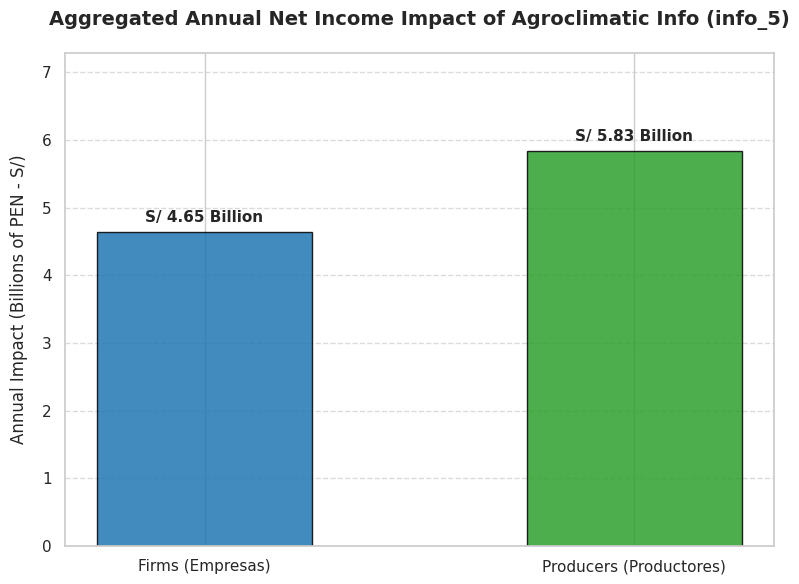

In [24]:
import matplotlib.pyplot as plt

# Prepare the data
groups = ['Firms (Empresas)', 'Producers (Productores)']
# Values in billions of Soles
annual_impacts_billions = [annual_impact_emp_soles / 1e9, annual_impact_pro_soles / 1e9]

# Create the bar chart
fig, ax = plt.subplots(figsize=(8, 6))
colors = ['#1f77b4', '#2ca02c']

bars = ax.bar(groups, annual_impacts_billions, color=colors, width=0.5, edgecolor='black', alpha=0.85)

# Customizing labels and titles
ax.set_title('Aggregated Annual Net Income Impact of Agroclimatic Info (info_5)', fontsize=14, fontweight='bold', pad=20)
ax.set_ylabel('Annual Impact (Billions of PEN - S/)', fontsize=12, labelpad=10)
ax.set_ylim(0, max(annual_impacts_billions) * 1.25)
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Adding value labels on top of the bars
for bar in bars:
    height = bar.get_height()
    ax.annotate(f'S/ {height:.2f} Billion\n({bar.get_x() + bar.get_width()/2:.2f})' if False else f'S/ {height:.2f} Billion',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 5),  # 5 points vertical offset
                textcoords="offset points",
                ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

In [25]:
import pandas as pd
import numpy as np

# Coefficients and p-values compiled from all estimation steps:
# 1. Log Models:
# Firms log_vbpagri (Production): info_5 = 1.5420 (p = 0.0024)
# Producers log_vbpagri (Production): info_5 = 0.4099 (p = 0.0028)
# Firms log_ingagri (Net Income): info_5 = 1.6685 (p = 0.0005)
# Producers log_ingagri (Net Income): info_5 = 0.1207 (p = 0.6207)
#
# 2. Level Models:
# Firms t_vbpagri (Production): info_5 = 12,890.0 (p = 0.2922)
# Producers t_vbpagri (Production): info_5 = 21.120 (p = 0.0002)
# Firms t_ingagri (Net Income): info_5 = 8,179.5298 (p = 0.4334)
# Producers t_ingagri (Net Income): info_5 = 9.2343 (p = 0.0116)

all_specs_data = {
    'Model Metric': [
        'Log Specification - Agroclimatic Info (info_5) Coeff',
        'Log Specification - P-value',
        'Log Specification - Observations (N)',
        'Levels Specification - Agroclimatic Info (info_5) Coeff',
        'Levels Specification - P-value',
        'Levels Specification - Observations (N)'
    ],
    'Firms: Production Value (vbpagri)': [
        1.5420, 0.0024, 2227,
        12890.0, 0.2922, 2227
    ],
    'Producers: Production Value (vbpagri)': [
        0.4099, 0.0028, 95499,
        21.1200, 0.0002, 95499
    ],
    'Firms: Net Income (ingagri)': [
        1.6685, 0.0005, 1352,
        8179.5298, 0.4334, 2227
    ],
    'Producers: Net Income (ingagri)': [
        0.1207, 0.6207, 45680,
        9.2343, 0.0116, 95499
    ]
}

df_all_specs = pd.DataFrame(all_specs_data)

# Helper to format with significance stars
def format_row(coeff, p_val, is_n=False):
    if is_n:
        return f"{int(coeff):,}"
    if pd.isna(coeff):
        return "-"
    stars = ""
    if p_val < 0.01:
        stars = "***"
    elif p_val < 0.05:
        stars = "**"
    elif p_val < 0.1:
        stars = "*"
    return f"{coeff:,.4f}{stars}"

formatted_rows = []
for idx, row in df_all_specs.iterrows():
    metric = row['Model Metric']
    if 'P-value' in metric:
        continue

    is_log = 'Log' in metric
    is_n = 'Observations' in metric

    p_idx = idx + 1 if not is_n else None

    formatted_row = {'Metric / Variable': metric.replace(' - Agroclimatic Info (info_5) Coeff', '').replace(' - Observations (N)', ' (N)')}

    for col in df_all_specs.columns[1:]:
        val = row[col]
        p_val = df_all_specs.loc[p_idx, col] if p_idx is not None else None
        formatted_row[col] = format_row(val, p_val, is_n)

    formatted_rows.append(formatted_row)

summary_all_specs = pd.DataFrame(formatted_rows)
print("=== COMPREHENSIVE REGRESSION SPECIFICATION SUMMARY (info_5 IMPACT) ===")
print("Significance Levels: *** p<0.01, ** p<0.05, * p<0.1\n")
display(summary_all_specs)

=== COMPREHENSIVE REGRESSION SPECIFICATION SUMMARY (info_5 IMPACT) ===
Significance Levels: *** p<0.01, ** p<0.05, * p<0.1



,Metric / Variable,Firms: Production Value (vbpagri),Producers: Production Value (vbpagri),Firms: Net Income (ingagri),Producers: Net Income (ingagri)
0,Log Specification,1.5420***,0.4099***,1.6685***,0.1207
1,Log Specification (N),"2,227","95,499","1,352","45,680"
2,Levels Specification,"12,890.0000",21.1200***,"8,179.5298",9.2343**
3,Levels Specification (N),"2,227","95,499","2,227","95,499"
